# Prioritized Replay Meets Predictive Maps: Agents Trained in the Proposed Mazes

This notebook implements the model-training component of the project proposal. The seven agents specified in the proposal are
placed in the three specified environments (§1–§2) and trained following the proposal's protocol (§3–§4). The notebook reports
only the training logs produced by the runs; evaluation metrics and statistical analyses are outside its scope.

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('.')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); plt.rcParams.update({'figure.dpi': 90})
from agents import AGENTS
from envs import get_spec, verify_spec, TASKS
from experiments.config import agent_kwargs, MAX_TRAIN_EPISODES, CRITERION_WINDOW, CRITERION_SUCCESS, POST_EPISODES
from experiments.train import train
from viz import plots

## 1  Environments

Each task is a stochastic gridworld with the Gymnasium interface. The maze is a $3\times3$ arrangement of $9\times9$ rooms joined by
single-cell doorways, i.e. a $29\times29$ lattice with 738 states. The four actions are the cardinal moves. With probability 0.10 the
executed action is replaced by one of the other three directions; a move into a wall leaves the agent in place. Reward is delivered
only on entering a goal cell, which ends the episode; episodes are truncated after 1 000 steps. Each task has one fixed layout and an
environmental change that is applied after training:

* **Reward revaluation.** Two goals at equal distance (68 steps) with rewards 1.0 and 0.5; the reward values are exchanged.
* **Transition revaluation.** A high-reward goal (1.0; 44 steps) and a nearer low-reward goal (0.7; 35 steps). The doorway of the
  high-reward room is moved to the opposite wall, which lengthens the route to 96 steps. Rewards are unchanged.
* **Tolman detour.** A single goal (44 steps). A doorway on the learned route is closed, leaving a 96-step detour. A converse
  *shortcut* variant (`tolman_shortcut`), in which a doorway opens, is also available.

In [2]:
pd.DataFrame([dict(task=t, lattice=verify_spec(get_spec(t))['shape'], states=verify_spec(get_spec(t))['n_open_union'],
                   shortest_path_before=list(verify_spec(get_spec(t))['dist_pre'].values()),
                   shortest_path_after=list(verify_spec(get_spec(t))['dist_post'].values())) for t in TASKS])

,task,lattice,states,shortest_path_before,shortest_path_after
0,reward_revaluation,"(29, 29)",738,"[68, 68]","[68, 68]"
1,transition_revaluation,"(29, 29)",738,"[44, 35]","[96, 35]"
2,tolman_detour,"(29, 29)",738,[44],[96]


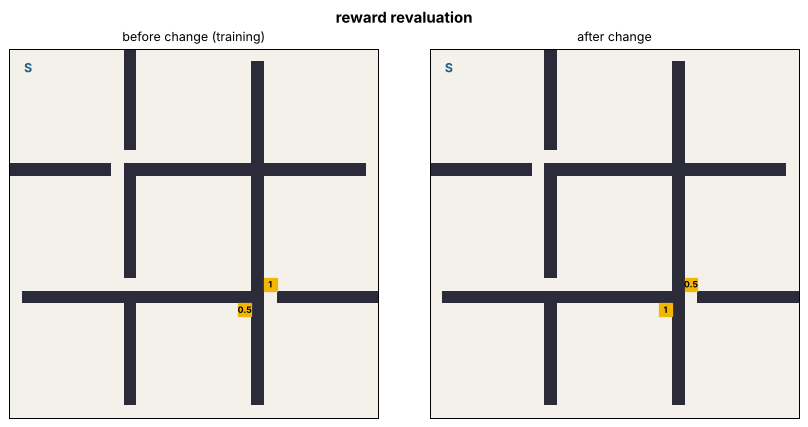

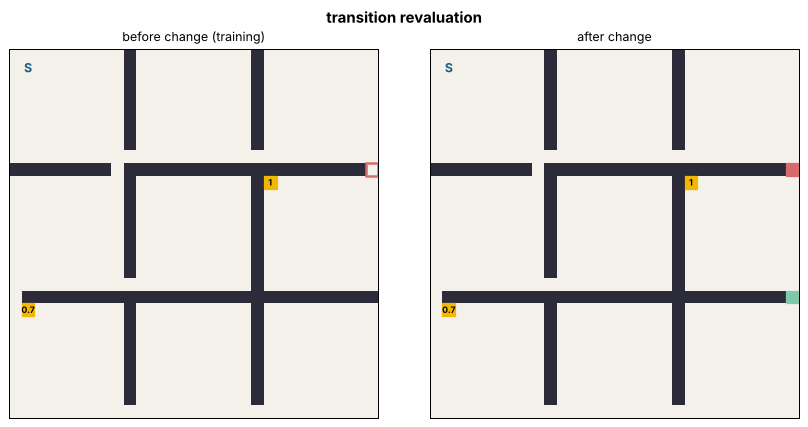

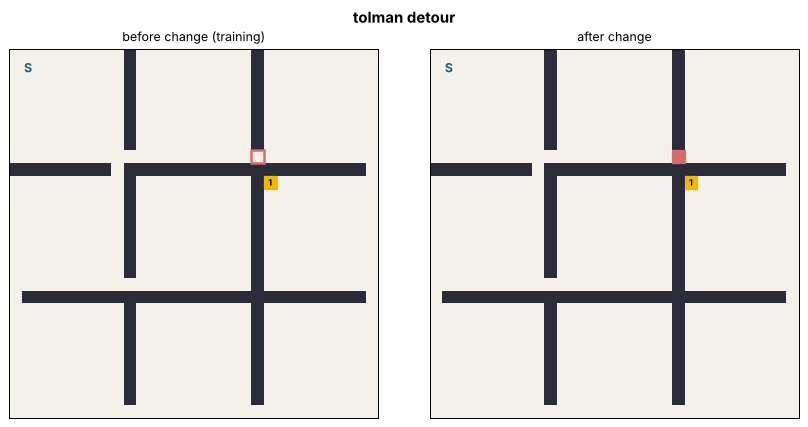

In [3]:
for t in TASKS:
    plots.plot_task_overview(get_spec(t)); plt.show()

*Legend.* S: start; yellow squares: goals (annotated with their reward); red: doorway that closes; green: doorway that opens.
State indices enumerate the cells that are open in either phase, so that tabular agents keep the same state space across the change.

## 2  Agents

All agents are tabular and act $\epsilon$-greedily; the replay agents share one replay implementation, so that they differ only in
what is replayed and how replayed items are selected.

| Agent | Bio-inspired component | Role |
|:--|:--|:--|
| `q_learning` | temporal-difference learning (Schultz et al., 1997) | model-free baseline |
| `dyna_q` | uniform offline replay (Sutton, 1991) | replay baseline |
| `model_based_planner` | planning over a learned model (value iteration) | upper-bound reference |
| `sr_td` | successor-representation predictive map (Dayan, 1993; Russek et al., 2017) | SR baseline |
| `sr_dyna` | SR with uniform off-policy replay | ablation: no prioritization |
| `prioritized_q` | need × gain replay on a Q-table (Mattar & Daw, 2018) | ablation: no SR |
| `sr_prioritized` | SR with need × gain prioritized replay | **main agent** |

The SR agents estimate $Q(s,a)=\sum_{s'a'}H(sa,s'a')\,w(s'a')$. $H$ is learned by the temporal-difference update
$H(sa,\cdot)\leftarrow H(sa,\cdot)+\alpha_{SR}[\mathbf 1_{sa}+\gamma H(s'a',\cdot)-H(sa,\cdot)]$, and the weights by
$w\leftarrow w+\alpha_{TD}\,\delta\,H(sa,\cdot)$ with $\delta=r+\gamma Q(s'a')-Q(sa)$, as specified in the proposal. Prioritized replay orders
backups by $\mathrm{EVB}=\mathrm{Gain}\times\mathrm{Need}$, where *Need* is obtained from the SR row of the agent's current state; the $n$-step
(sequence-extending) backup of Mattar and Daw (2018) is available through `max_seq_len`. Replay agents perform $k$ backups per
environment step (`replay_budget`; the proposal's ablation values are $\{0,5,20,50\}$). Default hyper-parameters:

In [4]:
pd.DataFrame({a: pd.Series(agent_kwargs(a)) for a in AGENTS}).T.fillna('')

,alpha,alpha_sr,alpha_td,epsilon,forget,gamma,plan_every,replay_budget,reward_mode
q_learning,0.1,,,0.1,,0.99,,,
dyna_q,0.1,,,0.1,,0.99,,20.0,
model_based_planner,,,,0.1,0.95,0.99,10.0,,
sr_td,,0.01,0.002,0.1,,0.99,,,td
sr_dyna,,0.01,0.002,0.1,,0.99,,20,td
prioritized_q,0.1,,,0.1,,0.99,,20.0,
sr_prioritized,,0.01,0.002,0.1,,0.99,,20,td


## 3  Training protocol

Following the proposal, each agent is trained in the original maze until it reaches a goal in at least 90 % of its last 20 episodes,
with a maximum of 500 episodes. `train(..., n_post=200)` then applies the environmental change and continues for 200 episodes.
A single integer seed controls the agent's stochastic choices and the environment's slips through two independent random streams.
Each episode is logged with its number of steps, total reward, whether (and which) goal was reached, the number of replay updates,
and its run time; every transition (state, action, reward, next state, done) can additionally be stored (`log_steps=True`).

```python
from experiments.train import train
result = train('transition_revaluation', 'sr_prioritized', seed=0, n_post=200)   # full protocol
result.episodes     # per-episode log          result.agent  # trained agent          result.env  # maze (after the change)
```
The same call is available from the command line (`python train.py --task ... --agent ... --seed ... --post 200`).

## 4  Training the agents in the mazes

Every agent is trained in every maze. A complete protocol run (up to 500 episodes of up to 1 000 steps) takes seconds for the
inexpensive agents but minutes to tens of minutes for the replay-prioritized ones, so this notebook caps the number of training
episodes at 15 in order to remain executable; the agents are therefore not expected to have met the criterion here. The full protocol
is obtained by omitting `max_episodes`.

In [5]:
DEMO_EPISODES = 15
results, rows = {}, []
for task in TASKS:
    for name in AGENTS:
        r = train(task, name, seed=0, max_episodes=DEMO_EPISODES)
        results[(task, name)] = r
        rows.append(dict(task=task, agent=name, episodes_trained=r.meta['train_episodes'],
                         goals_reached=int(r.episodes.reached_goal.sum()), env_steps=int(r.episodes.steps.sum()),
                         replay_updates=r.meta['total_replay_updates'], runtime_s=round(r.meta['total_runtime_s'], 1),
                         criterion_met=r.meta['criterion_met']))
pd.DataFrame(rows)

,task,agent,episodes_trained,goals_reached,env_steps,replay_updates,runtime_s,criterion_met
0,reward_revaluation,q_learning,15,0,15000,0,0.4,False
1,reward_revaluation,dyna_q,15,0,15000,300000,1.6,False
2,reward_revaluation,model_based_planner,15,0,15000,1717169,17.9,False
3,reward_revaluation,sr_td,15,0,15000,0,19.6,False
4,reward_revaluation,sr_dyna,15,0,15000,300000,25.8,False
5,reward_revaluation,prioritized_q,15,0,15000,290560,91.2,False
6,reward_revaluation,sr_prioritized,15,0,15000,293400,57.6,False
7,transition_revaluation,q_learning,15,2,14122,0,0.3,False
8,transition_revaluation,dyna_q,15,0,15000,300000,1.2,False
9,transition_revaluation,model_based_planner,15,9,7072,1962445,9.3,False


The first rows of the per-episode log of the main agent in the transition-revaluation maze:

In [6]:
results[('transition_revaluation', 'sr_prioritized')].episodes.head(8)

,task,agent,seed,phase,episode,steps,reward,reached_goal,goal_state,replay_updates,runtime_s
0,transition_revaluation,sr_prioritized,0,pre,1,1000,0.0,False,-1,18360,3.323093
1,transition_revaluation,sr_prioritized,0,pre,2,1000,0.0,False,-1,19980,3.320760
2,transition_revaluation,sr_prioritized,0,pre,3,1000,0.0,False,-1,18540,3.232062
3,transition_revaluation,sr_prioritized,0,pre,4,1000,0.0,False,-1,20000,3.759017
4,transition_revaluation,sr_prioritized,0,pre,5,1000,0.0,False,-1,19580,3.389495
5,transition_revaluation,sr_prioritized,0,pre,6,1000,0.0,False,-1,20000,3.867922
6,transition_revaluation,sr_prioritized,0,pre,7,1000,0.0,False,-1,20000,3.874859
7,transition_revaluation,sr_prioritized,0,pre,8,1000,0.0,False,-1,17980,3.514631


State-visit counts of the trained main agent illustrate that each agent operates within the walls of its maze (colour: $\log_{10}$ of the
number of visits; yellow squares: goals; S: start). After only 15 episodes the agent is still largely exploring near the start.

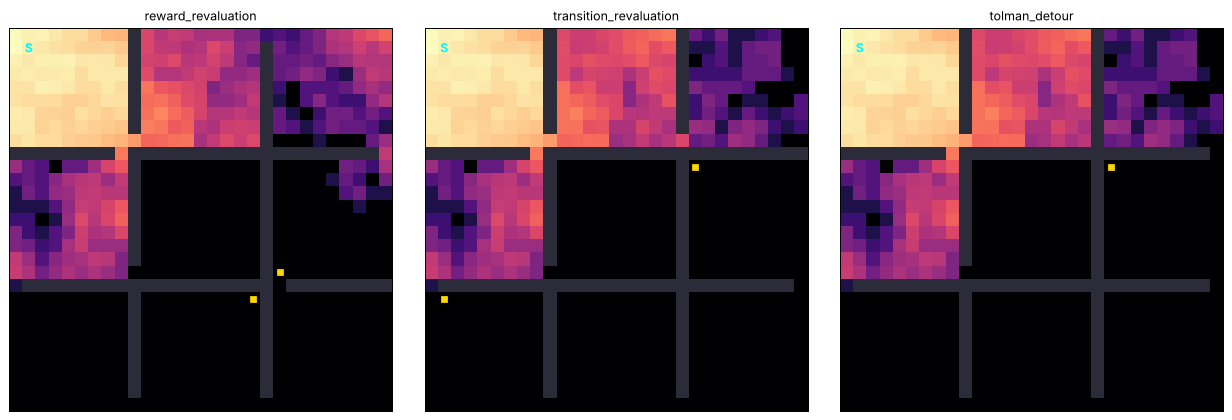

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, task in zip(axs, TASKS):
    r = results[(task, 'sr_prioritized')]; env = r.env
    plots.plot_heatmap(env, np.log10(1 + r.visits['pre']), ax, cmap='magma', colorbar=False, title=task)
    for g in env.goal_states:
        rr, cc = env.cell_of(g); ax.plot(cc, rr, 's', color='gold', ms=6, mec='k')
    rr, cc = env.cell_of(env.start_state); ax.text(cc, rr, 'S', color='cyan', ha='center', va='center', fontweight='bold')
fig.tight_layout(); plt.show()

## 5  Notes on the implementation

The agent code supplied by the team was extended to match the proposal notebook:
(i) $n$-step (sequence-extending) backups were added for `prioritized_q` and `sr_prioritized`, which the proposal introduces for studying forward replay;
(ii) the replay-event log was made compact (float32 chunks with batch identifiers) so that long runs remain feasible;
(iii) the SR agents maintain $Q=Hw$ incrementally instead of recomputing it at every step, which reduces the cost of the main agent without changing its behaviour.
At $\gamma=0.99$ the entries of $H$ grow as $(1-\gamma)^{-1}$; the SR learning rate is therefore set to $\alpha_{SR}=0.01$ and $\alpha_{TD}=0.002$ by default, and
these values, like the remaining hyper-parameters, are intended to be tuned on the separate tuning seeds specified in the proposal.
The optional agents of the proposal (distributional agent, DQN, keys-and-doors extension, agentic memory controller) are not included.

## References

Dayan, P. (1993). Improving generalization for temporal difference learning: The successor representation. *Neural Computation, 5*(4), 613–624.
Mattar, M. G., & Daw, N. D. (2018). Prioritized memory access explains planning and hippocampal replay. *Nature Neuroscience, 21*, 1609–1617.
Russek, E. M., Momennejad, I., Botvinick, M. M., Gershman, S. J., & Daw, N. D. (2017). Predictive representations can link model-based reinforcement learning to model-free mechanisms. *PLOS Computational Biology, 13*(9), e1005768.
Schultz, W., Dayan, P., & Montague, P. R. (1997). A neural substrate of prediction and reward. *Science, 275*, 1593–1599.
Sutton, R. S. (1991). Dyna, an integrated architecture for learning, planning, and reacting. *SIGART Bulletin, 2*(4), 160–163.

## 6  Hand-off to the evaluation metrics

The metrics themselves are not computed here, but everything they need is recorded (details in `README.md`):

* `result.episodes` - after every **post-change** episode, the exact start-state return of the greedy policy (`J_greedy`, i.e. $J_e$) and of the
  $\epsilon$-greedy behaviour policy (`J_behavior`, for regret), with the reference returns `J_star` and `J_rand` of the changed maze
  (`experiments/reference.py`; discounted with the task $\gamma$, 1000-step cap ignored).
* `log_replay='post'|'all'` - every replay backup (direction/context labels via `classify_replay_direction`, `classify_replay_context`).
* `result.snapshots` - Q table and state-level SR matrix $M$ at the end of each phase; `result.env.adjacency()` gives the Moran's $I$ weights.
* `experiments.runs.run_grid / load_runs` - many seeds, agents and ablation variants (`variants={'k=5': dict(replay_budget=5)}`) in a standard folder layout.
  Seeds: tune on `TUNE_SEEDS`, report on `EVAL_SEEDS`.

In [ ]:
from experiments.config import TUNE_SEEDS, EVAL_SEEDS
r = train('transition_revaluation', 'sr_prioritized', seed=0, max_episodes=5, n_post=3, log_replay='post')   # tiny demo
r.episodes[r.episodes.phase == 'post'][['episode', 'J_greedy', 'J_behavior', 'J_star', 'J_rand']]